<center><h1>Chen_Chien-Ting_HW7</h1></center>

Name: Chien-Ting Chen
<br>
Github Username: jessica91816
<br>
USC ID: 2009118611

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram
import matplotlib.pyplot as plt
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '1'

### (a) Download the Anuran Calls (MFCCs) Data Set

In [7]:
df = pd.read_csv('Frogs_MFCCs.csv', sep=',')
X = df.drop(['Family', 'Genus', 'Species', 'RecordID'], axis=1)
y = df[['Family', 'Genus', 'Species']]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, shuffle=True)

### (b) Train a classifier for each label

#### (i) Research

* Exact match: A sample is considered correctly predicted only when all predicted labels match the true labels. The exact match score is the proportion of samples for which all labels are predicted correctly.
* Hamming loss: The number of incorrectly predicted labels divided by the total number of label predictions. A smaller value indicates better performance.
* Hamming score: In this assignment, I define Hamming score as 1 - Hamming loss. A higher value indicates better performance.

#### (ii) Train a SVM for each of the labels

In [12]:
searches = {}
for label in ['Family','Genus','Species']:
    y_target = y_train[label]
    svm_family = OneVsRestClassifier(SVC(kernel='rbf'))
    param_grid = {
        'estimator__C':[1, 10, 100, 1000],
        'estimator__gamma':[0.1, 1, 10]}
    search_family = GridSearchCV(
        estimator=svm_family,
        param_grid=param_grid,
        cv=10,
        scoring='accuracy'
    )
    search_family.fit(X_train, y_target)
    searches[label] = search_family
    print(label, search_family.best_params_)
    print(label, search_family.best_score_)

Family {'estimator__C': 100, 'estimator__gamma': 1}
Family 0.9920575751838177
Genus {'estimator__C': 10, 'estimator__gamma': 1}
Genus 0.990070292530531
Species {'estimator__C': 10, 'estimator__gamma': 1}
Species 0.9898706964561835


In [13]:
predictions={}
for label in ['Family','Genus','Species']:
    search_family = searches[label]
    predictions[label] = search_family.predict(X_test)
y_pred = pd.DataFrame(predictions, index=y_test.index)
correct =  (y_pred == y_test)
exact_match = correct.all(axis=1).mean()
hamming_score = correct.to_numpy().mean()
hamming_loss = 1 - hamming_score
print(f'Exact match: {exact_match}')
print(f'Hamming score: {hamming_score}')
print(f'Hamming loss: {hamming_loss}')

Exact match: 0.9874942102825383
Hamming score: 0.9922803767176162
Hamming loss: 0.007719623282383847


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [15]:
searches_l1 = {}
for label in ['Family','Genus','Species']:
    y_target = y_train[label]
    svm_family = OneVsRestClassifier(LinearSVC(penalty='l1', dual=False, max_iter=100000))
    param_grid = {'svm__estimator__C':[0.1, 1, 10, 100]}
    pip = Pipeline([('scaler', StandardScaler()),('svm', svm_family)])
    search_family = GridSearchCV(
        estimator=pip,
        param_grid=param_grid,
        cv=10,
        scoring='accuracy'
    )
    search_family.fit(X_train, y_target)
    searches_l1[label] = search_family
    print(label, search_family.best_params_)
    print(label, search_family.best_score_)

Family {'svm__estimator__C': 1}
Family 0.9406288459717882
Genus {'svm__estimator__C': 10}
Genus 0.9527422764997319
Species {'svm__estimator__C': 10}
Species 0.9602847202499291


In [16]:
predictions_l1={}
for label in ['Family','Genus','Species']:
    search_family = searches_l1[label]
    predictions_l1[label] = search_family.predict(X_test)
y_pred_l1 = pd.DataFrame(predictions_l1, index=y_test.index)
correct_l1 =  (y_pred_l1 == y_test)
exact_match_l1 = correct_l1.all(axis=1).mean()
hamming_score_l1 = correct_l1.to_numpy().mean()
hamming_loss_l1 = 1 - hamming_score_l1
print(f'Exact match: {exact_match_l1}')
print(f'Hamming score: {hamming_score_l1}')
print(f'Hamming loss: {hamming_loss_l1}')

Exact match: 0.9129226493747105
Hamming score: 0.9431835726416551
Hamming loss: 0.05681642735834491


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [18]:
for label in ['Family','Genus','Species']:
    y_counts = y_train[label].value_counts()
    print(label, y_counts)

Family Family
Leptodactylidae    3073
Hylidae            1542
Dendrobatidae       380
Bufonidae            41
Name: count, dtype: int64
Genus Genus
Adenomera        2899
Hypsiboas        1125
Ameerega          380
Dendropsophus     226
Leptodactylus     174
Scinax            111
Osteocephalus      80
Rhinella           41
Name: count, dtype: int64
Species Species
AdenomeraHylaedactylus    2447
HypsiboasCordobae          788
AdenomeraAndre             452
Ameeregatrivittata         380
HypsiboasCinerascens       337
HylaMinuta                 226
LeptodactylusFuscus        174
ScinaxRuber                111
OsteocephalusOophagus       80
Rhinellagranulosa           41
Name: count, dtype: int64


In [19]:
searches_smote = {}
for label in ['Family','Genus','Species']:
    y_target = y_train[label]
    svm_family = OneVsRestClassifier(LinearSVC(penalty='l1', dual=False, max_iter=100000))
    param_grid = {'svm__estimator__C':[0.1, 1, 10, 100]}
    pip_smote = ImbPipeline(
        [('scaler', StandardScaler()), ('smote', SMOTE(random_state=42)), ('svm', svm_family)])
    search_family = GridSearchCV(
        estimator=pip_smote,
        param_grid=param_grid,
        cv=10,
        scoring='accuracy'
    )
    search_family.fit(X_train, y_target)
    searches_smote[label] = search_family
    print(label, search_family.best_params_)
    print(label, search_family.best_score_)

Family {'svm__estimator__C': 1}
Family 0.9209725772350028
Genus {'svm__estimator__C': 10}
Genus 0.9124325475717127
Species {'svm__estimator__C': 1}
Species 0.9571069614061661


In [20]:
predictions_smote={}
for label in ['Family','Genus','Species']:
    search_family = searches_smote[label]
    predictions_smote[label] = search_family.predict(X_test)
y_pred_smote = pd.DataFrame(predictions_smote, index=y_test.index)
correct_smote =  (y_pred_smote == y_test)
exact_match_smote = correct_smote.all(axis=1).mean()
hamming_score_smote = correct_smote.to_numpy().mean()
hamming_loss_smote = 1 - hamming_score_smote
print(f'Exact match: {exact_match_smote}')
print(f'Hamming score: {hamming_score_smote}')
print(f'Hamming loss: {hamming_loss_smote}')

Exact match: 0.8517832329782307
Hamming score: 0.9223405897792187
Hamming loss: 0.07765941022078127


The Gaussian SVM performed best across all three test metrics. Adding SMOTE resulted in worse overall performance than the L1 linear SVM without SMOTE. Therefore, SMOTE did not improve predictive performance on this dataset.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [24]:
# I use the CH score to select k. 
#Since it requires at least two clusters, we evaluate k from 2 to 50.
ch_score = {}
for k in range(2, 51):
    kmeans = KMeans(n_clusters=k, random_state=42).fit(X)
    ch_score[k] = calinski_harabasz_score(X, kmeans.labels_)
max_k = max(ch_score, key=ch_score.get)
print(f'Best k = {max_k}')

Best k = 2


In [25]:
best_kmeans = KMeans(n_clusters=max_k, random_state=42).fit(X)
cluster_labels = best_kmeans.labels_
print(cluster_labels)

[1 1 1 ... 1 1 1]


### (b) Determine which family is the majority

In [27]:
cluster_df = y.copy()
cluster_df['Cluster'] = cluster_labels
cluster_group = cluster_df.groupby('Cluster')[['Family','Genus','Species']]
majority_group = cluster_group.agg(lambda s: s.mode().iloc[0])
print(majority_group)

                  Family      Genus                 Species
Cluster                                                    
0        Leptodactylidae  Adenomera  AdenomeraHylaedactylus
1                Hylidae  Hypsiboas       HypsiboasCordobae


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [29]:
y_cluster_pred = pd.DataFrame(index=y.index)
for label in ['Family','Genus','Species']:
    y_cluster_pred[label] = cluster_df['Cluster'].map(majority_group[label])
wrong = (y_cluster_pred != y)
hamming_distance = wrong.sum(axis=1).mean()
hamming_loss = wrong.to_numpy().mean()
hamming_score = 1 - hamming_loss
print(f'average Hamming Distance: {hamming_distance}')
print(f'Hamming Loss: {hamming_loss}')
print(f'Hamming Score: {hamming_score}')

average Hamming Distance: 0.8956219596942321
Hamming Loss: 0.2985406532314107
Hamming Score: 0.7014593467685892


In [30]:
distance = []
loss = []
score = []
for seed in range(50):
    ch_score = {}
    for k in range(2, 51):
        kmeans = KMeans(n_clusters=k, random_state=seed).fit(X)
        ch_score[k] = calinski_harabasz_score(X, kmeans.labels_)
    max_k = max(ch_score, key=ch_score.get)
    best_kmeans = KMeans(n_clusters=max_k, random_state=seed).fit(X)
    cluster_labels = best_kmeans.labels_
    cluster_df = y.copy()
    cluster_df['Cluster'] = cluster_labels
    cluster_group = cluster_df.groupby('Cluster')[['Family','Genus','Species']]
    majority_group = cluster_group.agg(lambda s: s.mode().iloc[0])
    y_cluster_pred = pd.DataFrame(index=y.index)
    for label in ['Family','Genus','Species']:
        y_cluster_pred[label] = cluster_df['Cluster'].map(majority_group[label])
    wrong = (y_cluster_pred != y)
    hamming_distance = wrong.sum(axis=1).mean()
    hamming_loss = wrong.to_numpy().mean()
    hamming_score = 1 - hamming_loss
    distance.append(hamming_distance)
    loss.append(hamming_loss)
    score.append(hamming_score)
summary_df = pd.DataFrame({
    'Metric':['Average Hamming distance', 'Hamming Loss', 'Hamming Score'],
    'Mean':[np.mean(distance), np.mean(loss), np.mean(score)],
    'Std':[np.std(distance), np.std(loss), np.std(score)]})
print(summary_df.round(6))

                     Metric      Mean  Std
0  Average Hamming distance  0.895622  0.0
1              Hamming Loss  0.298541  0.0
2             Hamming Score  0.701459  0.0


## 3. ISLR 12.6.2

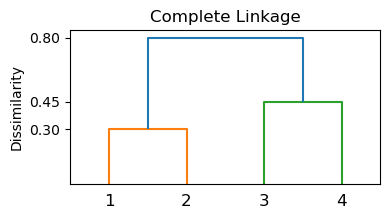

In [32]:
plt.figure(figsize=(4,2))
Z = np.array([[0, 1, 0.3, 2],
            [2, 3, 0.45, 2],
            [4, 5, 0.8, 4]])
dendrogram(Z, labels=['1', '2', '3', '4'])
plt.ylabel('Dissimilarity')
plt.title('Complete Linkage')
plt.yticks([0.3, 0.45, 0.8])
plt.show()

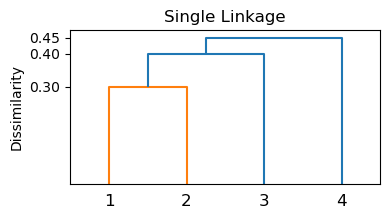

In [33]:
plt.figure(figsize=(4,2))
Z = np.array([[0, 1, 0.3, 2],
            [4, 2, 0.4, 3],
            [5, 3, 0.45, 4]])
dendrogram(Z, labels=['1', '2', '3', '4'])
plt.ylabel('Dissimilarity')
plt.yticks([0.3, 0.4, 0.45])
plt.title('Single Linkage')
plt.show()

* (c) {1,2} and {3,4}
* (d) {1,2,3} and {4}

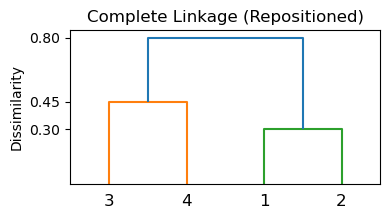

In [35]:
plt.figure(figsize=(4,2))
Z = np.array([
            [2, 3, 0.45, 2],
            [0, 1, 0.3, 2],
            [4, 5, 0.8, 4]])
dendrogram(Z, labels=['1', '2', '3', '4'])
plt.ylabel('Dissimilarity')
plt.yticks([0.3, 0.45, 0.8])
plt.title('Complete Linkage (Repositioned)')
plt.show()